## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

random_state = 42
n_init = 20

## Chargement et preprocessing

In [2]:
X_train = pd.read_csv('Données/X_train_clean.csv')
y_train = pd.read_csv('Données/Y_train_clean.csv')

print(f'Shape de X_train : {X_train.shape}')
print(f'Valeurs manquantes : {X_train.isna().sum().sum()}')

num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
X_num = X_train[num_cols]

numeric_cols = X_num.columns.tolist()
print(f"Colonnes numériques : {numeric_cols}")

Shape de X_train : (444, 34)
Valeurs manquantes : 0
Colonnes numériques : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Asymmetry', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'Expression_Data_Missing']


In [3]:
X_train['TE_Coverage_Mean'].describe()

count    444.000000
mean       5.563647
std        6.651536
min        0.000000
25%        0.000000
50%        3.602688
75%        8.576138
max       47.548340
Name: TE_Coverage_Mean, dtype: float64

### Distribution variables 

Variables catégorielles (12) : ['TE_Env_Pair_TE-free_TE-free', 'TE_Env_Pair_TE-free_TE-poor', 'TE_Env_Pair_TE-free_TE-rich', 'TE_Env_Pair_TE-poor_TE-poor', 'TE_Env_Pair_TE-poor_TE-rich', 'TE_Env_Pair_TE-rich_TE-rich', 'TE_Env_Class_free', 'TE_Env_Class_half', 'TE_Env_Class_rich', 'Pfam_Asymmetry', 'TE_Env_Match', 'Expression_Data_Missing']
Variables continues (22) : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean']


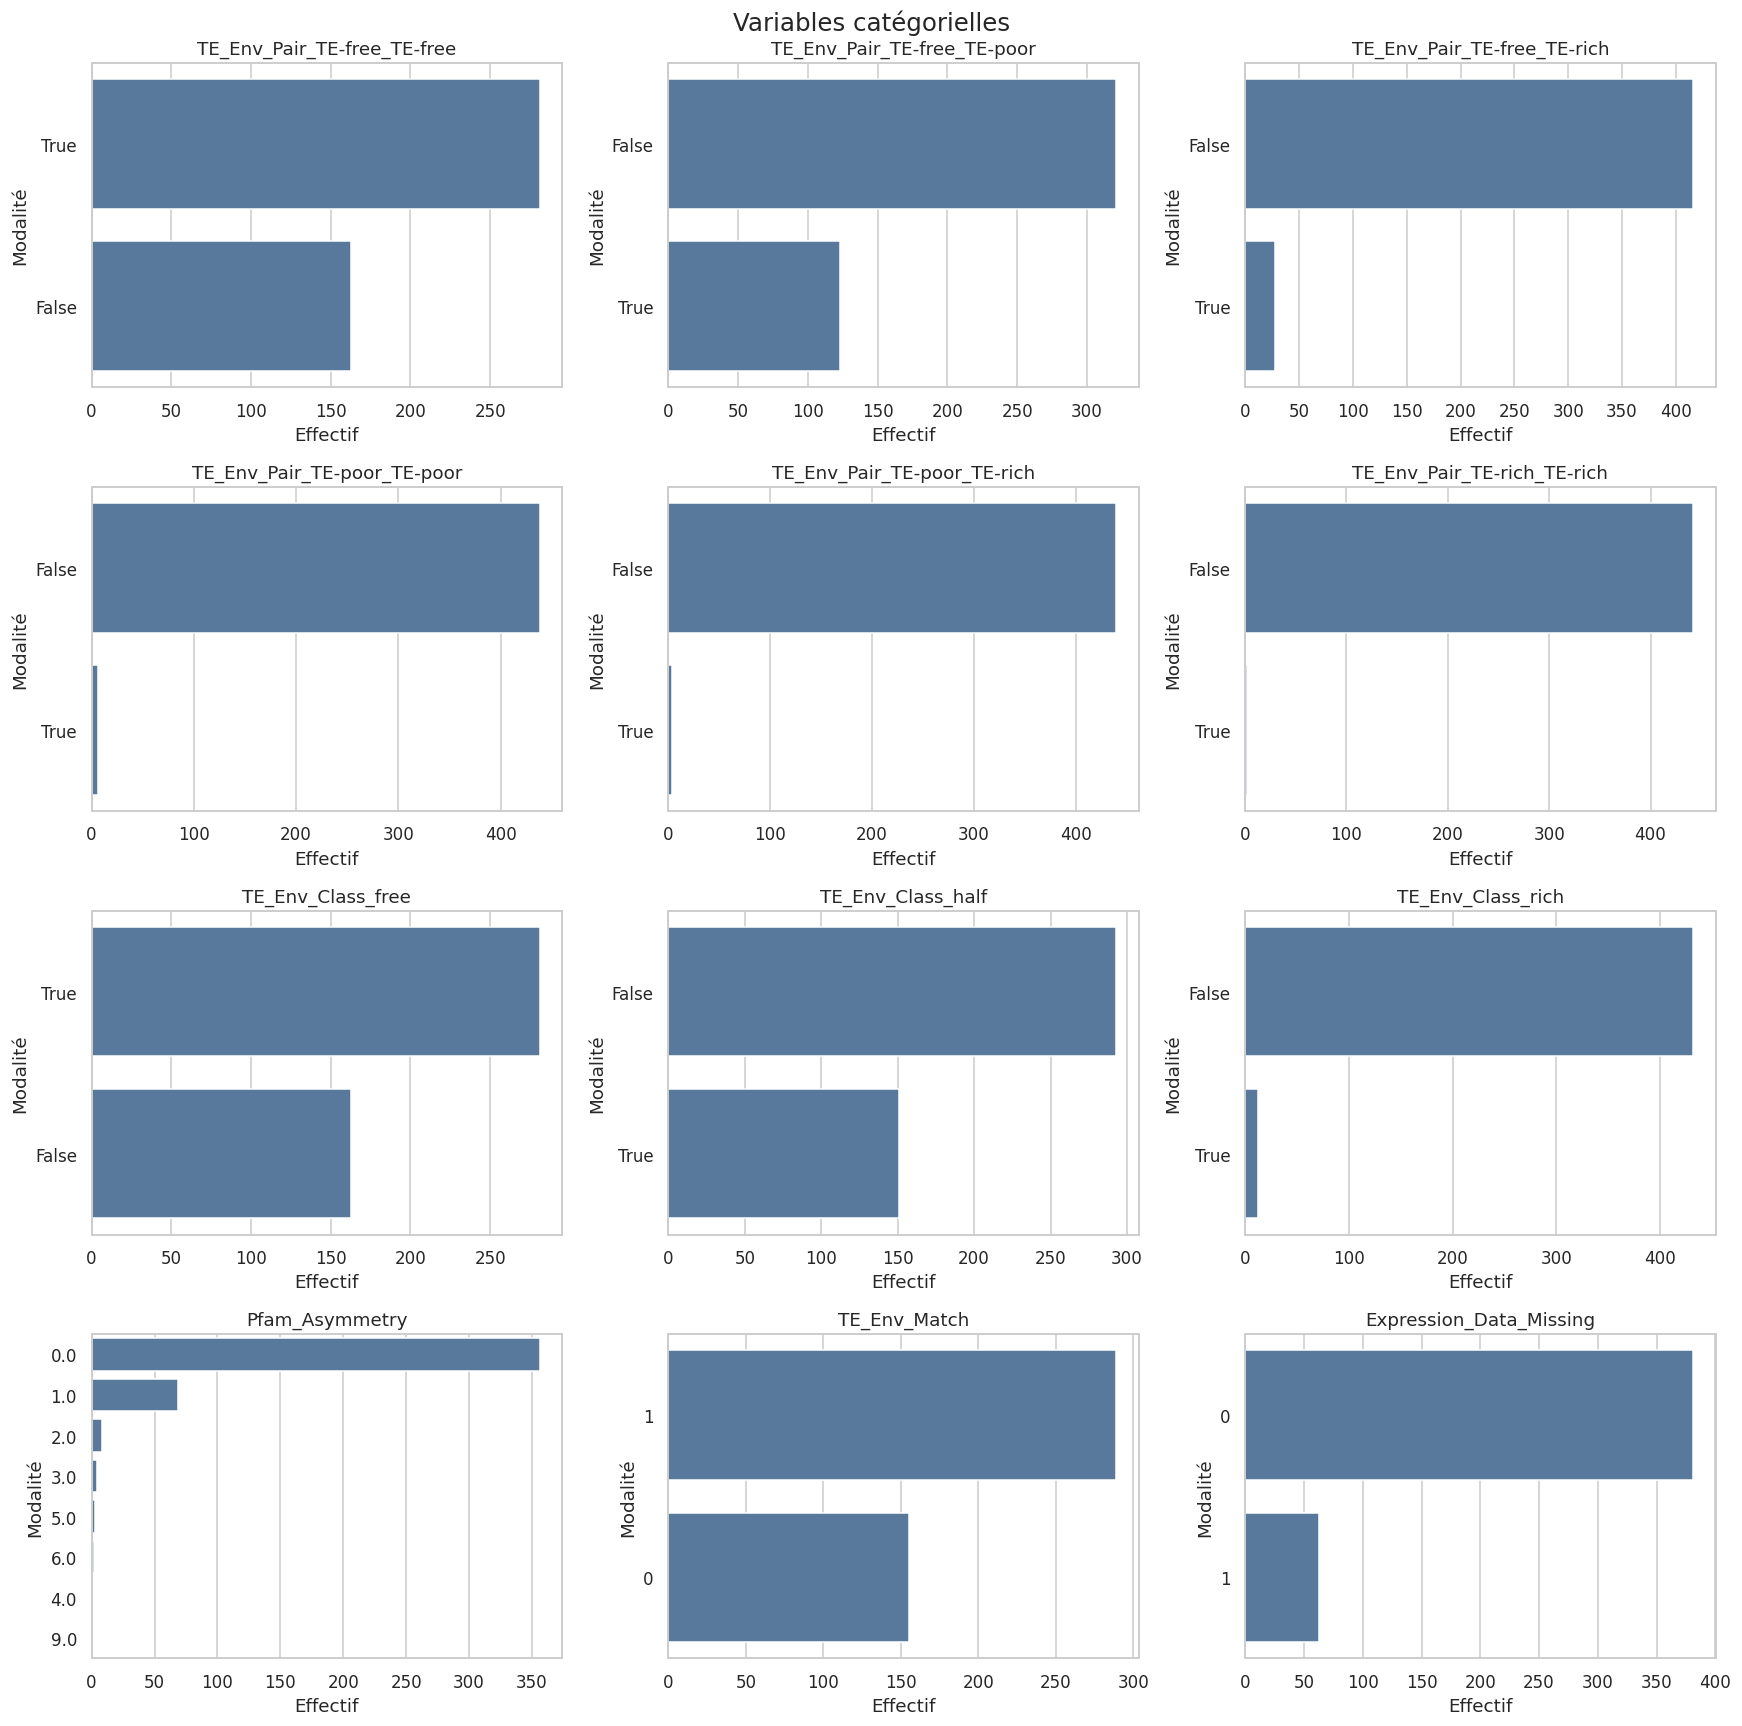

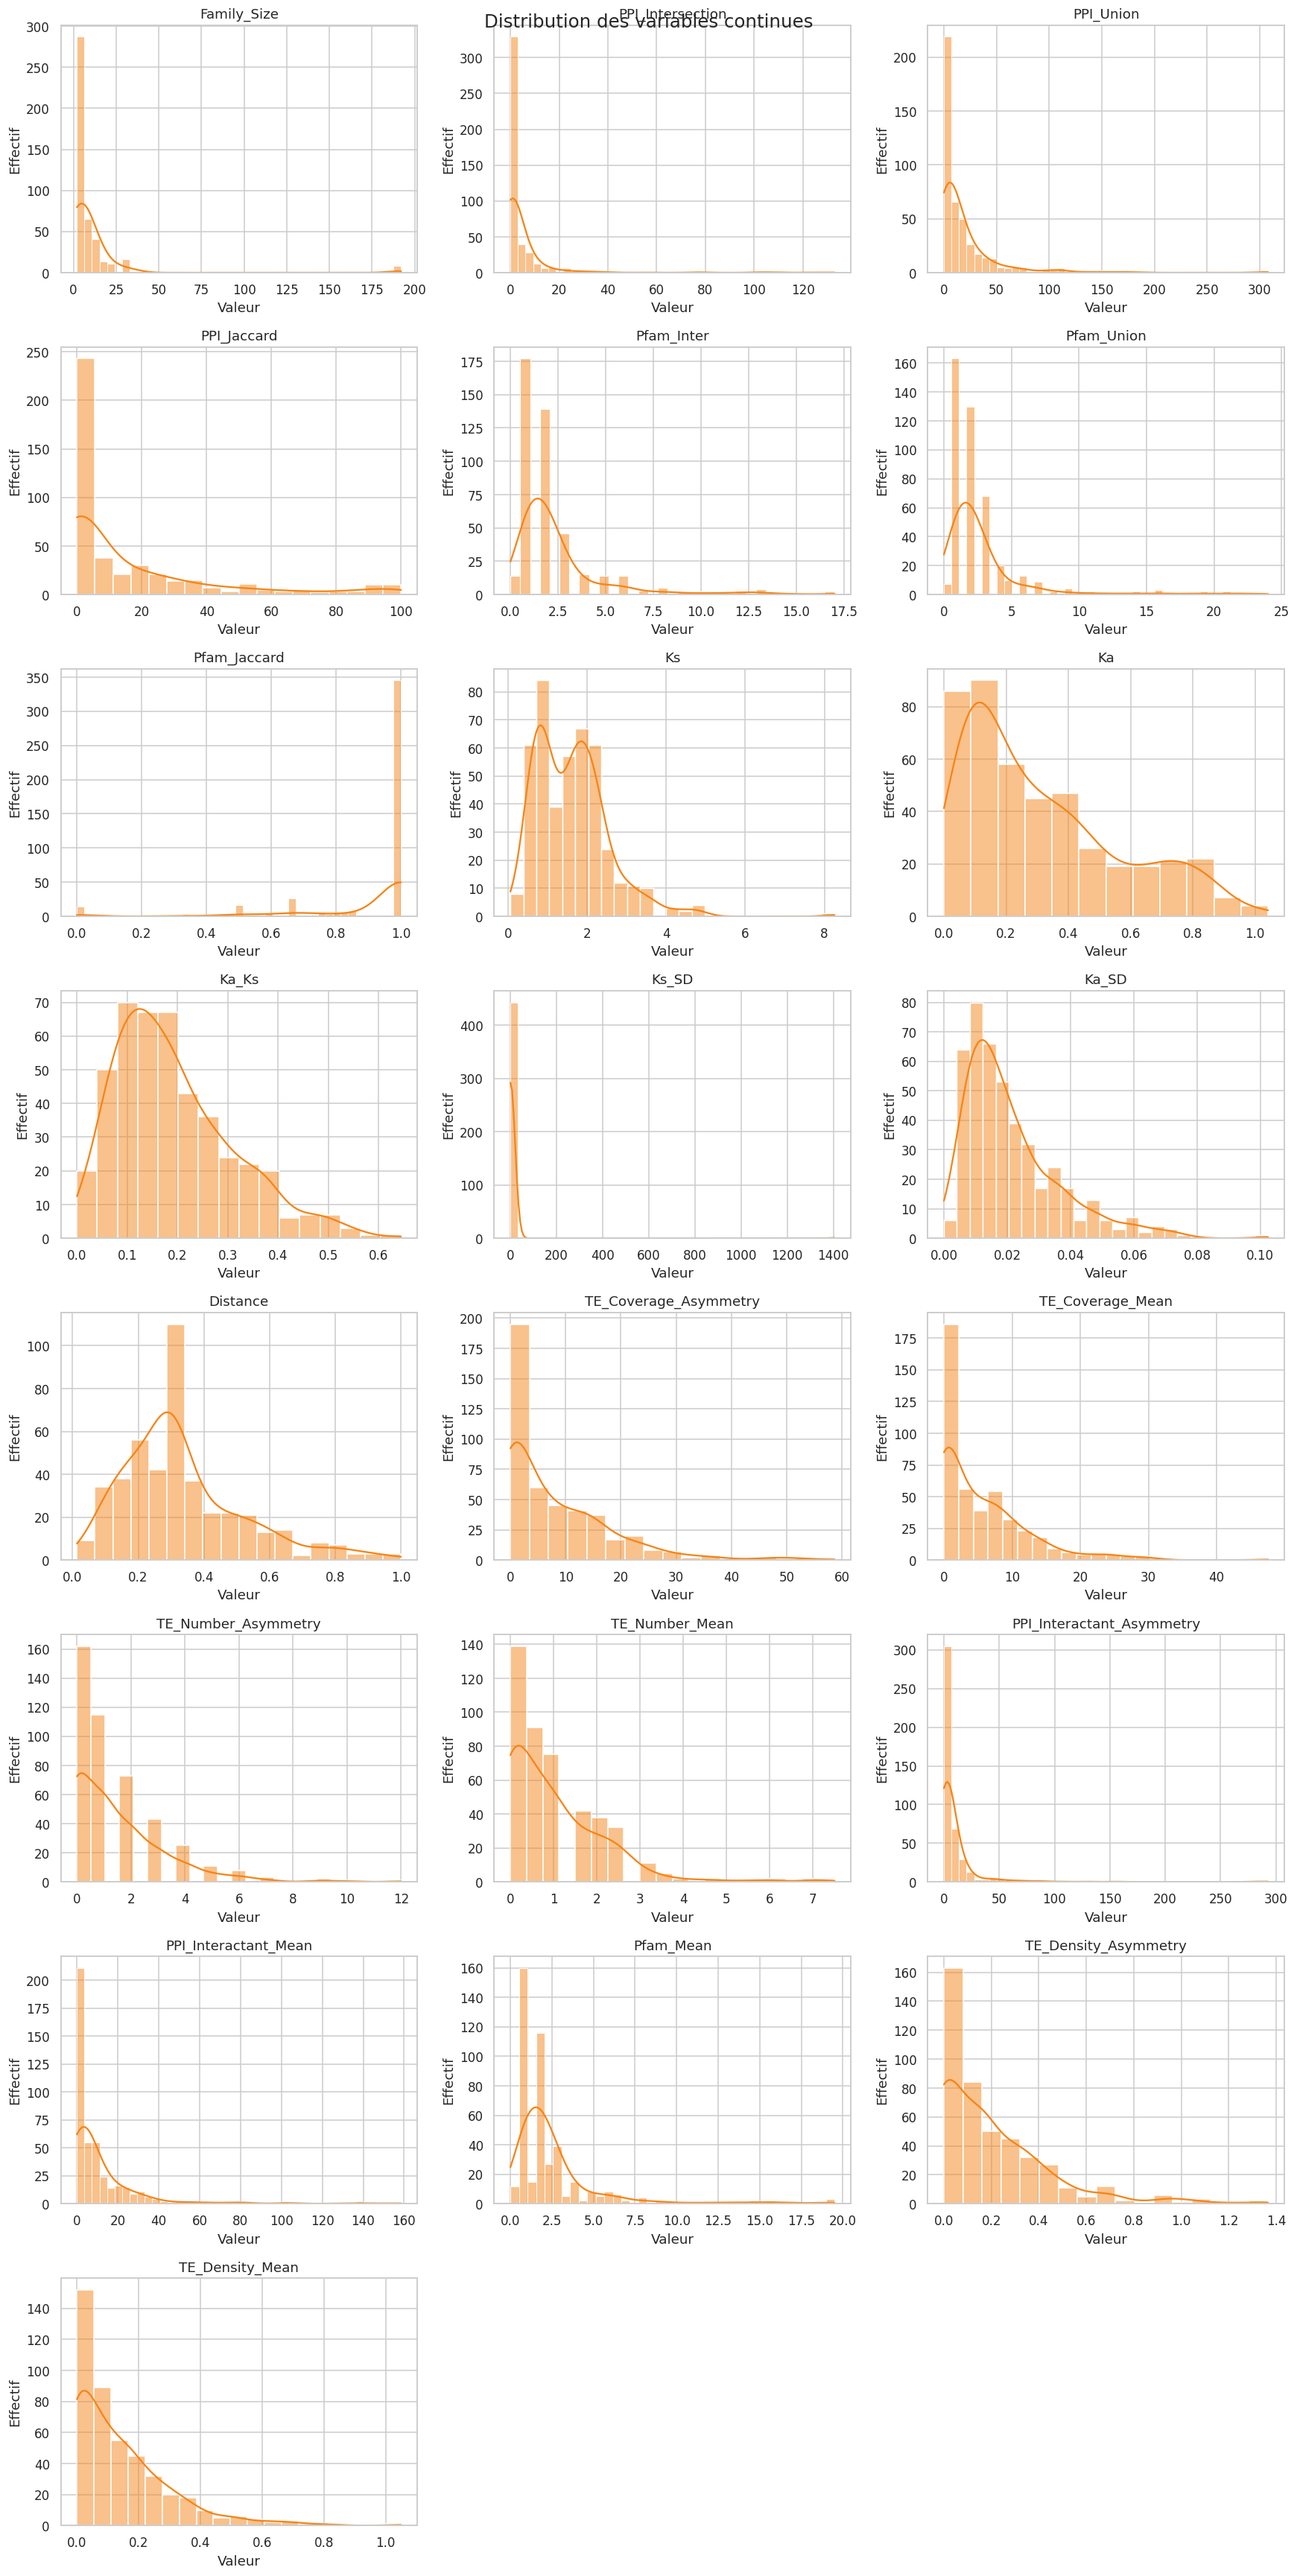

In [4]:
# Distribution des variables catégorielles et continues de X_train
max_categories = 10
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
encoded_categorical_cols = [
    column for column in numeric_cols
    if X_train[column].nunique(dropna=True) <= max_categories
]
categorical_cols = list(dict.fromkeys(categorical_cols + encoded_categorical_cols))
continuous_cols = [column for column in numeric_cols if column not in categorical_cols]

print(f"Variables catégorielles ({len(categorical_cols)}) : {categorical_cols}")
print(f"Variables continues ({len(continuous_cols)}) : {continuous_cols}")

if categorical_cols:
    n_columns = 3
    n_rows = int(np.ceil(len(categorical_cols) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, column in zip(axes, categorical_cols):
        counts = X_train[column].astype('object').fillna('Valeur manquante').value_counts().head(20)
        sns.barplot(x=counts.values, y=counts.index.astype(str), ax=axis, color='#4C78A8')
        axis.set_title(column)
        axis.set_xlabel('Effectif')
        axis.set_ylabel('Modalité')

    for axis in axes[len(categorical_cols):]:
        axis.remove()
    fig.suptitle('Variables catégorielles', fontsize=16)
    fig.tight_layout()
    plt.show()

if continuous_cols:
    n_columns = 3
    n_rows = int(np.ceil(len(continuous_cols) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, column in zip(axes, continuous_cols):
        sns.histplot(data=X_train, x=column, kde=True, ax=axis, color='#F58518')
        axis.set_title(column)
        axis.set_xlabel('Valeur')
        axis.set_ylabel('Effectif')

    for axis in axes[len(continuous_cols):]:
        axis.remove()
    fig.suptitle('Distribution des variables continues', fontsize=16)
    fig.tight_layout()
    plt.show()


## Linear Discriminant Analysis

In [5]:
# Supprimer les variables exclues de l'analyse LDA
X_all = X_num.drop(
    columns=['Ka_SD', 'Ks_SD', 'Expression_Data_Missing']).copy()

y = y_train['Classification'].reset_index(drop=True)
X_all = X_all.reset_index(drop=True)

if len(X_all) != len(y):
    raise ValueError('X_all et y_train n ont pas le meme nombre de lignes.')

scaler_lda = StandardScaler()
X_all_scaled = scaler_lda.fit_transform(X_all)

n_components = min(2, len(y_train['Classification'].dropna().unique()) - 1)
lda = LinearDiscriminantAnalysis(n_components=n_components)
X_lda = lda.fit_transform(X_all_scaled, y_train['Classification'])

if n_components == 1:
    df_lda = pd.DataFrame({'LDA_1': X_lda[:, 0], 'Classification': y_train['Classification']})
else:
    df_lda = pd.DataFrame(X_lda, columns=['LDA_1', 'LDA_2'])
    df_lda['Classification'] = y_train['Classification']

print('Shape apres LDA :', X_lda.shape)

Shape apres LDA : (444, 1)


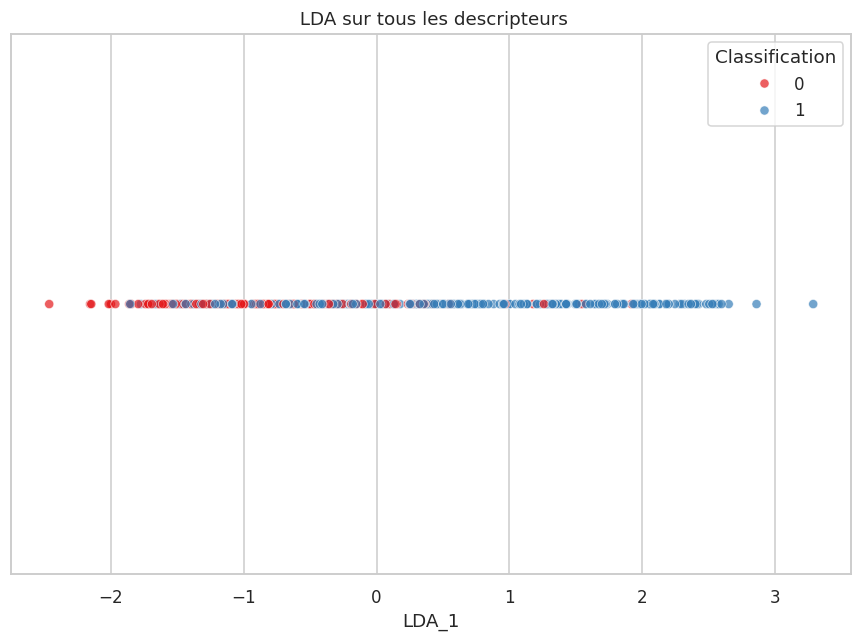

In [6]:
plt.figure(figsize=(8, 6))
if n_components == 1:
    sns.scatterplot(
        data=df_lda, x='LDA_1', y=np.zeros(len(df_lda)),
        hue='Classification', palette='Set1', alpha=0.7
    )
    plt.ylabel('')
    plt.yticks([])
else:
    sns.scatterplot(
        data=df_lda, x='LDA_1', y='LDA_2',
        hue='Classification', palette='Set1', alpha=0.7
    )
plt.title(' LDA sur tous les descripteurs')
plt.tight_layout()
plt.show()

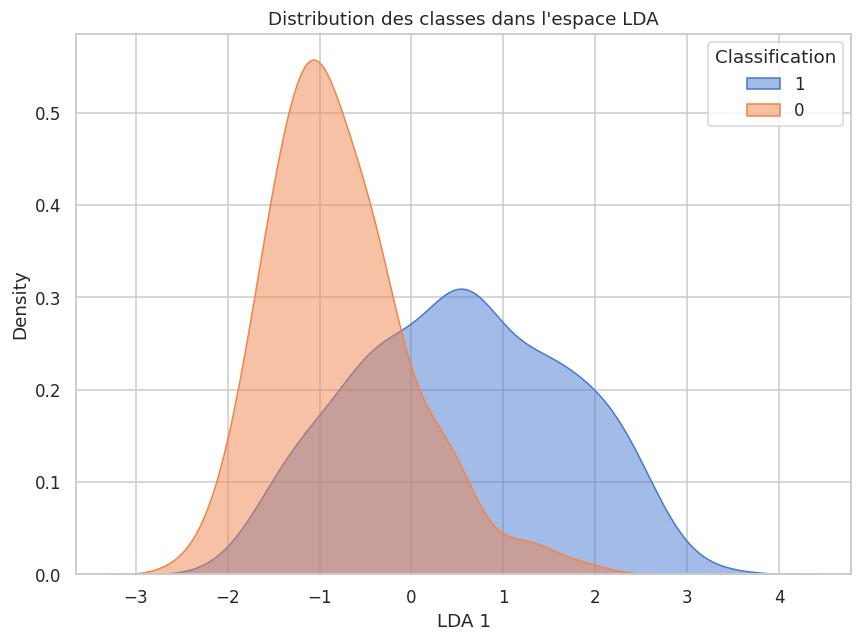

In [7]:
plt.figure(figsize=(8, 6))
if n_components == 1:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(df_lda[df_lda['Classification'] == cls]['LDA_1'], label=cls, fill=True, alpha=0.5)
    plt.xlabel('LDA 1')
else:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(
            x=df_lda[df_lda['Classification'] == cls]['LDA_1'],
            y=df_lda[df_lda['Classification'] == cls]['LDA_2'],
            label=cls,
            fill=True,
            alpha=0.5
        )
    plt.xlabel('LDA 1')
    plt.ylabel('LDA 2')
plt.title('Distribution des classes dans l\'espace LDA')
plt.legend(title='Classification')
plt.tight_layout()
plt.show()

In [8]:
coef_df = pd.DataFrame(lda.coef_, columns=X_all.columns).T
coef_df['max_abs_coef'] = coef_df.abs().max(axis=1)
coef_df_sorted = coef_df.sort_values('max_abs_coef', ascending=False)

print('Tableau des 10 meilleurs coefficients de la LDA :')
coef_df_sorted.head(10)

Tableau des 10 meilleurs coefficients de la LDA :


,0,max_abs_coef
Ka,1.161781,1.161781
TE_Density_Asymmetry,-1.149021,1.149021
TE_Coverage_Mean,-0.868582,0.868582
TE_Density_Mean,0.770585,0.770585
TE_Number_Asymmetry,0.555377,0.555377
TE_Coverage_Asymmetry,0.433027,0.433027
PPI_Jaccard,-0.391012,0.391012
TE_Number_Mean,0.292995,0.292995
PPI_Interactant_Mean,0.278637,0.278637
PPI_Union,0.263000,0.263000


## K-means sur les cinq meilleurs descripteurs

### Selection dynamique des 5 meilleurs descripteurs (hors `_Mean`)

On repart du classement `coef_df_sorted` etabli par la LDA (coefficient absolu maximal), en excluant les descripteurs dont le nom se termine par `_Mean`, puis on garde les 5 premiers.


In [9]:
ranking_no_mean = coef_df_sorted[~coef_df_sorted.index.str.endswith('_Mean')]
selected_descriptors = ranking_no_mean.head(5).index.tolist()

print('Descripteurs selectionnes (top 5, hors _Mean) :')
print(selected_descriptors)

missing_descriptors = [
    column for column in selected_descriptors
    if column not in X_train.columns
]
if missing_descriptors:
    raise KeyError(f'Descripteurs absents : {missing_descriptors}')


Descripteurs selectionnes (top 5, hors _Mean) :
['Ka', 'TE_Density_Asymmetry', 'TE_Number_Asymmetry', 'TE_Coverage_Asymmetry', 'PPI_Jaccard']


## Pipeline K-means par descripteur

Pour chaque descripteur selectionne :

- **Descripteurs `_Asymmetry`** : un premier cluster (cluster `0`) est cree de facon deterministe, contenant les lignes ou le descripteur `_Asymmetry` vaut 0 du au fait que `descripteur_G1 = descripteur_G2 = 0`
- **Autres descripteurs** (pas de suffixe `_Asymmetry`) : toutes les valeurs valides passent directement dans le K-means principal, pas de premier cluster.

**Hypotheses retenues pour le tableau recapitulatif (a ajuster si besoin, voir les constantes en tete de la cellule suivante)** :
- Plage de K testee : 1 a 10 (un K est ignore s'il est superieur ou egal au nombre de points disponibles).
- *ARI moyen / ARI median* : mesure de stabilite. Le K-means est relance `n_stability_runs` fois avec des graines aleatoires differentes pour le meme K, puis l'ARI est calcule entre toutes les paires de partitions obtenues ; on rapporte la moyenne et la mediane de ces ARI.
- *BIC* : approximation gaussienne spherique classique (a la X-means / Pelleg & Moore), avec `p = (K-1) + K*d + 1` parametres libres (d = dimension, ici d = 1 par descripteur).
- *Partition non triviale ?* : vaut « Oui » si la plus petite taille de cluster est >= `min_cluster_size` (3 par defaut) **et** qu'aucun cluster ne depasse `max_cluster_frac` (90% par defaut) des points, « Non » sinon.
- Le K final retenu par descripteur est celui qui maximise la silhouette parmi les partitions non triviales (repli sur l'ensemble des partitions K>1 si aucune n'est non triviale).


### Comptage des zeros _Asymmetry

In [10]:
df_lamme = pd.read_csv('Données/lamme_training.csv')
print(f'{len(df_lamme):,} paires de gènes chargées.')

descriptors = {
    'TE_Density': ('TE_Density_G1', 'TE_Density_G2'),
    'TE_Coverage': ('TE_Coverage_G1', 'TE_Coverage_G2'),
    'TE_Number': ('TE_Number_G1', 'TE_Number_G2'),
}

required_columns = [column for pair in descriptors.values() for column in pair]
missing_columns = sorted(set(required_columns) - set(df_lamme.columns))
if missing_columns:
    raise KeyError(f'Colonnes manquantes : {missing_columns}')

df_lamme[required_columns].head()

444 paires de gènes chargées.


,TE_Density_G1,TE_Density_G2,TE_Coverage_G1,TE_Coverage_G2,TE_Number_G1,TE_Number_G2
0,0.167056,0.193424,1.318826,5.777292,1.0,1.0
1,0.167056,0.745712,1.318826,29.346681,1.0,3.0
2,0.000000,0.000000,0.000000,0.000000,0.0,0.0
3,0.200080,0.000000,15.273775,0.000000,1.0,0.0
4,0.200080,0.000000,15.273775,0.000000,1.0,0.0


In [11]:
results = []
zero_pair_masks = {}

for descriptor, (gene1_column, gene2_column) in descriptors.items():
    valid_values = df_lamme[[gene1_column, gene2_column]].notna().all(axis=1)
    both_zero = (df_lamme[gene1_column] == 0) & (df_lamme[gene2_column] == 0)
    zero_pair_mask = valid_values & both_zero
    zero_pair_masks[descriptor] = zero_pair_mask.reset_index(drop=True)

    results.append({
        'Descripteur': descriptor,
        'Nombre total de paires': len(df_lamme),
        'Paires analysables': int(valid_values.sum()),
        'Paires avec G1 = G2 = 0': int(zero_pair_mask.sum()),
        'Pourcentage des paires analysables': round(100 * zero_pair_mask.sum() / valid_values.sum(), 2)
        if valid_values.sum() else 0.0,
        'Valeurs manquantes': int((~valid_values).sum()),
    })
results_df_lamme = pd.DataFrame(results)
for _, row in results_df_lamme.iterrows():
    print(f"{row['Descripteur']}: {row['Paires avec G1 = G2 = 0']} paires")

results_df_lamme

TE_Density: 139 paires
TE_Coverage: 139 paires
TE_Number: 139 paires


,Descripteur,Nombre total de paires,Paires analysables,Paires avec G1 = G2 = 0,Pourcentage des paires analysables,Valeurs manquantes
0,TE_Density,444,444,139,31.31,0
1,TE_Coverage,444,444,139,31.31,0
2,TE_Number,444,444,139,31.31,0


In [12]:
from itertools import combinations

# Constantes ajustables
k_values = list(range(1, 11))
n_stability_runs = 10
min_cluster_size = 22 # 5% du nombre total de paires 
max_cluster_frac = 0.9


def compute_bic(X, labels, centers):
    """BIC approx gaussienne spherique (style X-means / Pelleg & Moore)."""
    n, d = X.shape
    k = centers.shape[0]
    n_i = np.bincount(labels, minlength=k).astype(float)

    ss = 0.0
    for i in range(k):
        pts = X[labels == i]
        if len(pts) > 0:
            ss += np.sum((pts - centers[i]) ** 2)

    dof = n - k
    if dof <= 0:
        return np.nan
    variance = ss / dof
    if variance <= 0:
        return np.nan

    log_lik = 0.0
    for i in range(k):
        if n_i[i] == 0:
            continue
        log_lik += (
            -n_i[i] / 2 * np.log(2 * np.pi)
            - n_i[i] * d / 2 * np.log(variance)
            - (n_i[i] - 1) / 2
            + n_i[i] * np.log(n_i[i])
            - n_i[i] * np.log(n)
        )

    n_params = (k - 1) + k * d + 1
    return log_lik - (n_params / 2) * np.log(n)


def kmeans_stability(X, k, n_runs, base_seed, n_init):
    """Relance le K-means n_runs fois (graines differentes) et calcule les ARI par paire."""
    labelings, inertias = [], []
    for run in range(n_runs):
        model = KMeans(n_clusters=k, n_init=n_init, random_state=base_seed + run)
        labels = model.fit_predict(X)
        labelings.append(labels)
        inertias.append(model.inertia_)
    aris = [
        adjusted_rand_score(a, b)
        for a, b in combinations(labelings, 2)
    ]
    return labelings, inertias, aris


def kmeans_grid_summary(X, k_values, n_runs=n_stability_runs, base_seed=random_state,
                         n_init=n_init, min_cluster_size=min_cluster_size,
                         max_cluster_frac=max_cluster_frac):
    """Construit le tableau recapitulatif Inertie/Silhouette/ARI/BIC pour une plage de K."""
    n = X.shape[0]
    rows = []

    for k in k_values:
        if k == 1:
            center = X.mean(axis=0, keepdims=True)
            inertia = float(np.sum((X - center) ** 2))
            rows.append({
                'K': k, 'Inertie': inertia, 'Silhouette': np.nan,
                'ARI moyen': np.nan, 'ARI median': np.nan,
                'Taille min': np.nan, 'Taille max': np.nan,
                'Partition non triviale ?': np.nan, 'BIC': np.nan
            })
            continue

        if k >= n:
            continue

        labelings, inertias, aris = kmeans_stability(X, k, n_runs, base_seed, n_init)
        best_idx = int(np.argmin(inertias))
        labels = labelings[best_idx]

        if len(set(labels)) < 2:
            continue

        sizes = np.bincount(labels, minlength=k)
        sil = silhouette_score(X, labels)

        final_model = KMeans(n_clusters=k, n_init=n_init, random_state=base_seed).fit(X)
        bic = compute_bic(X, labels, final_model.cluster_centers_)

        non_trivial = bool(
            sizes.min() >= min_cluster_size and sizes.max() / n <= max_cluster_frac
        )

        rows.append({
            'K': k,
            'Inertie': inertias[best_idx],
            'Silhouette': sil,
            'ARI moyen': float(np.mean(aris)) if aris else np.nan,
            'ARI median': float(np.median(aris)) if aris else np.nan,
            'Taille min': float(sizes.min()),
            'Taille max': float(sizes.max()),
            'Partition non triviale ?': 'Oui' if non_trivial else 'Non',
            'BIC': bic
        })

    return pd.DataFrame(rows)


### Boucle principale : premier cluster (Asymmetry) + grille K-means par descripteur


In [13]:
descriptor_summaries = {}
labels_by_descriptor = {}

# Conversion de X_all_scaled en DataFrame avec les noms de colonnes
X_all_scaled_df = pd.DataFrame(
    X_all_scaled,
    columns=X_all.columns,
    index=X_train.index
)

for descriptor in selected_descriptors:
    values_scaled = pd.to_numeric(
        X_all_scaled_df[descriptor],
        errors='coerce'
    )

    labels_full = pd.Series(
        index=X_train.index,
        dtype='Int64'
    )

    if descriptor.endswith('_Asymmetry'):
        mean_descriptor = descriptor.replace('_Asymmetry', '_Mean')

        if mean_descriptor not in X_all.columns:
            raise KeyError(f'Colonne absente : {mean_descriptor}')

        base_descriptor = descriptor.replace('_Asymmetry', '')

        if base_descriptor not in zero_pair_masks:
            raise KeyError(
                f"Masque des paires nulles absent pour : {base_descriptor}"
            )

        if len(zero_pair_masks[base_descriptor]) != len(X_train):
            raise ValueError(
                f"Longueur incompatible pour le masque de {base_descriptor}."
            )

        first_cluster_mask = pd.Series(
            zero_pair_masks[base_descriptor].to_numpy(),
            index=X_train.index,
            dtype=bool
        )

        labels_full.loc[first_cluster_mask] = 0
        remaining_mask = (
            values_scaled.notna()
            & ~first_cluster_mask
        )
        cluster_offset = 1

    else:
        remaining_mask = values_scaled.notna()
        cluster_offset = 0

    X_remaining_scaled = values_scaled.loc[
        remaining_mask
    ].to_numpy().reshape(-1, 1)

    if len(X_remaining_scaled) == 0:
        labels_by_descriptor[descriptor] = labels_full
        continue

    summary_df = kmeans_grid_summary(
        X_remaining_scaled,
        k_values
    )

    descriptor_summaries[descriptor] = summary_df

    print(f'Tableau récapitulatif K-means -- {descriptor}')
    display(summary_df)

    candidates = summary_df[summary_df['K'] > 1]
    non_trivial = candidates[
        candidates['Partition non triviale ?'] == 'Oui'
    ]

    pool = (
        non_trivial
        if not non_trivial.empty
        else candidates
    )

    if not pool.empty:
        best_row = pool.loc[
            pool['Silhouette'].idxmax()
        ]

        best_k = int(best_row['K'])

        final_model = KMeans(
            n_clusters=best_k,
            n_init=n_init,
            random_state=random_state
        )

        final_labels = final_model.fit_predict(
            X_remaining_scaled
        )

        labels_full.loc[
            values_scaled.loc[remaining_mask].index
        ] = final_labels + cluster_offset

        print(
            f'K retenu pour {descriptor} : {best_k}'
        )

    labels_by_descriptor[descriptor] = labels_full.astype('Int64')

Tableau récapitulatif K-means -- Ka


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,116.265396,0.650850,1.000000,1.000000,138.0,306.0,Oui,-619.901976
2,3,44.814539,0.640531,1.000000,1.000000,81.0,230.0,Oui,-588.611513
3,4,27.296425,0.599692,0.975384,1.000000,71.0,177.0,Oui,-1489.772119
4,5,18.323670,0.585226,0.997778,1.000000,41.0,174.0,Oui,-608.414146
5,6,13.406392,0.558952,0.887117,0.872483,38.0,150.0,Oui,-1511.472485
6,7,9.588770,0.560682,0.929991,0.896915,28.0,131.0,Oui,-1456.475256
7,8,7.684533,0.554007,0.937470,0.924093,28.0,96.0,Oui,-1303.627759
8,9,5.790354,0.556811,0.931900,0.940305,8.0,93.0,Non,-1850.598297
9,10,4.878662,0.554770,0.920018,0.918299,4.0,93.0,Non,-1594.204741


K retenu pour Ka : 2
Tableau récapitulatif K-means -- TE_Density_Asymmetry


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,296.201809,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,108.261695,0.680589,1.000000,1.000000,43.0,262.0,Oui,-410.323939
2,3,47.274448,0.620421,0.993552,0.987909,28.0,169.0,Oui,-1006.655367
3,4,26.284961,0.622274,1.000000,1.000000,13.0,156.0,Non,-409.057965
4,5,18.385962,0.608674,1.000000,1.000000,13.0,149.0,Non,-423.058233
5,6,12.764427,0.593337,1.000000,1.000000,13.0,122.0,Non,-448.670991
6,7,8.822151,0.598107,0.993935,1.000000,3.0,122.0,Non,-1185.778871
7,8,6.333850,0.593177,0.973897,0.989851,3.0,102.0,Non,-425.304749
8,9,4.567601,0.605377,0.975316,0.980287,3.0,102.0,Non,-1279.155514
9,10,3.496618,0.585855,0.888994,0.959690,3.0,77.0,Non,-1301.515980


K retenu pour TE_Density_Asymmetry : 2
Tableau récapitulatif K-means -- TE_Number_Asymmetry


...

K retenu pour TE_Number_Asymmetry : 2
Tableau récapitulatif K-means -- TE_Coverage_Asymmetry


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,307.071890,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,116.598955,0.638442,1.000000,1.000000,59.0,246.0,Oui,-447.389345
2,3,53.293463,0.607712,0.991285,0.988525,21.0,171.0,Non,-1020.447153
3,4,28.103923,0.609101,1.000000,1.000000,8.0,148.0,Non,-983.375388
4,5,19.031233,0.571882,0.979814,0.994929,8.0,128.0,Non,-1016.289428
5,6,11.629443,0.581776,0.978427,0.991928,7.0,108.0,Non,-1113.462531
6,7,8.706970,0.567021,0.974424,0.989945,7.0,85.0,Non,-1249.516041
7,8,6.871342,0.558135,0.984637,1.000000,7.0,71.0,Non,-1235.869500
8,9,5.208480,0.571504,0.948525,0.984572,7.0,71.0,Non,-1155.405393
9,10,4.334406,0.570023,0.859712,0.830175,3.0,71.0,Non,-1368.416604


K retenu pour TE_Coverage_Asymmetry : 2
Tableau récapitulatif K-means -- PPI_Jaccard


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,108.854900,0.773327,1.000000,1.000000,68.0,376.0,Oui,-520.207137
2,3,39.678026,0.749136,1.000000,1.000000,38.0,309.0,Oui,-465.133687
3,4,19.416252,0.750784,1.000000,1.000000,30.0,285.0,Oui,-406.893205
4,5,11.771266,0.753036,0.998523,0.998326,28.0,256.0,Oui,-1122.580535
5,6,7.793643,0.770221,0.965675,0.945018,18.0,243.0,Non,-1092.161682
6,7,5.103433,0.787043,0.995217,0.993174,14.0,242.0,Non,-325.255894
7,8,3.956333,0.780285,0.972012,0.986344,11.0,243.0,Non,-290.677527
8,9,3.047469,0.781511,0.990811,0.989728,10.0,241.0,Non,-1512.385827
9,10,2.476321,0.775230,0.981130,0.989081,10.0,238.0,Non,-1879.511597


K retenu pour PPI_Jaccard : 2


### Tailles de clusters finales (premier cluster inclus)


In [14]:
X_top_5 = X_train[selected_descriptors].copy()
scaler_top_5 = StandardScaler()
X_top_5_scaled = pd.DataFrame(
    scaler_top_5.fit_transform(X_top_5),
    columns=selected_descriptors,
    index=X_top_5.index
)

cluster_size_rows = []
for descriptor, labels in labels_by_descriptor.items():
    counts = labels.value_counts().sort_index()
    for cluster, size in counts.items():
        cluster_size_rows.append({
            'Descripteur': descriptor,
            'Cluster': int(cluster),
            'Taille': int(size)
        })

cluster_sizes_df = pd.DataFrame(cluster_size_rows)
display(cluster_sizes_df)


,Descripteur,Cluster,Taille
0,Ka,0,138
1,Ka,1,306
2,TE_Density_Asymmetry,0,139
3,TE_Density_Asymmetry,1,262
4,TE_Density_Asymmetry,2,43
5,TE_Number_Asymmetry,0,139
6,TE_Number_Asymmetry,1,211
7,TE_Number_Asymmetry,2,94
8,TE_Coverage_Asymmetry,0,139
9,TE_Coverage_Asymmetry,1,246


In [15]:
# Comparaison en conservant les identifiants réels des clusters

y_train = pd.read_csv("Données/Y_train_clean.csv")
classifications = y_train["Classification"].reset_index(drop=True)

cluster_sizes_by_descriptor = {}
cluster_ratios_by_descriptor = {}

# position du centre des clusters 

for descriptor in selected_descriptors:
    labels = labels_by_descriptor[descriptor].reset_index(drop=True)

    if len(labels) != len(classifications):
        raise ValueError(
            f"Nombre de labels incompatible pour {descriptor}."
        )

    valid_mask = labels.notna() & classifications.notna()

    labels_valid = labels.loc[valid_mask].astype(int)
    classifications_valid = classifications.loc[valid_mask]

    cluster_sizes = {}
    cluster_ratios = {}

    # Les identifiants réels sont conservés
    for cluster_id in sorted(labels_valid.unique()):
        cluster_mask = labels_valid == cluster_id

        n_points = int(cluster_mask.sum())
        n_redondant = int(
            ((classifications_valid == 0) & cluster_mask).sum()
        )
        n_divergent = int(
            ((classifications_valid == 1) & cluster_mask).sum()
        )

        ratio = (
            n_redondant / n_divergent
            if n_divergent > 0
            else np.inf
        )

        cluster_sizes[cluster_id] = n_points
        cluster_ratios[cluster_id] = ratio

    cluster_sizes_by_descriptor[descriptor] = cluster_sizes
    cluster_ratios_by_descriptor[descriptor] = cluster_ratios


# Nombre maximal d'identifiants de clusters
max_cluster_id = max(
    max(cluster_sizes.keys())
    for cluster_sizes in cluster_sizes_by_descriptor.values()
)

columns = [
    f"Cluster {cluster_id}"
    for cluster_id in range(max_cluster_id + 1)
]

cluster_comparison = pd.DataFrame(
    np.nan,
    index=selected_descriptors,
    columns=columns,
    dtype=float
)

ratio_comparison = pd.DataFrame(
    np.nan,
    index=selected_descriptors,
    columns=columns,
    dtype=float
)


# Remplissage selon les identifiants réels
for descriptor in selected_descriptors:
    cluster_sizes = cluster_sizes_by_descriptor[descriptor]
    cluster_ratios = cluster_ratios_by_descriptor[descriptor]

    for cluster_id in cluster_sizes:
        column = f"Cluster {cluster_id}"

        cluster_comparison.loc[
            descriptor, column
        ] = cluster_sizes[cluster_id]

        ratio_comparison.loc[
            descriptor, column
        ] = cluster_ratios[cluster_id]


# Annotations
annot_matrix = pd.DataFrame(
    "",
    index=cluster_comparison.index,
    columns=cluster_comparison.columns,
    dtype=object
)

for descriptor in cluster_comparison.index:
    for column in cluster_comparison.columns:
        n_points = cluster_comparison.loc[descriptor, column]
        ratio = ratio_comparison.loc[descriptor, column]

        if pd.isna(n_points):
            annot_matrix.loc[descriptor, column] = ""
        else:
            ratio_text = (
                f"{ratio:.2f}"
                if not np.isinf(ratio)
                else "inf"
            )

            annot_matrix.loc[descriptor, column] = (
                f"{int(n_points)} paires\n"
                f"R/D={ratio_text}"
            )



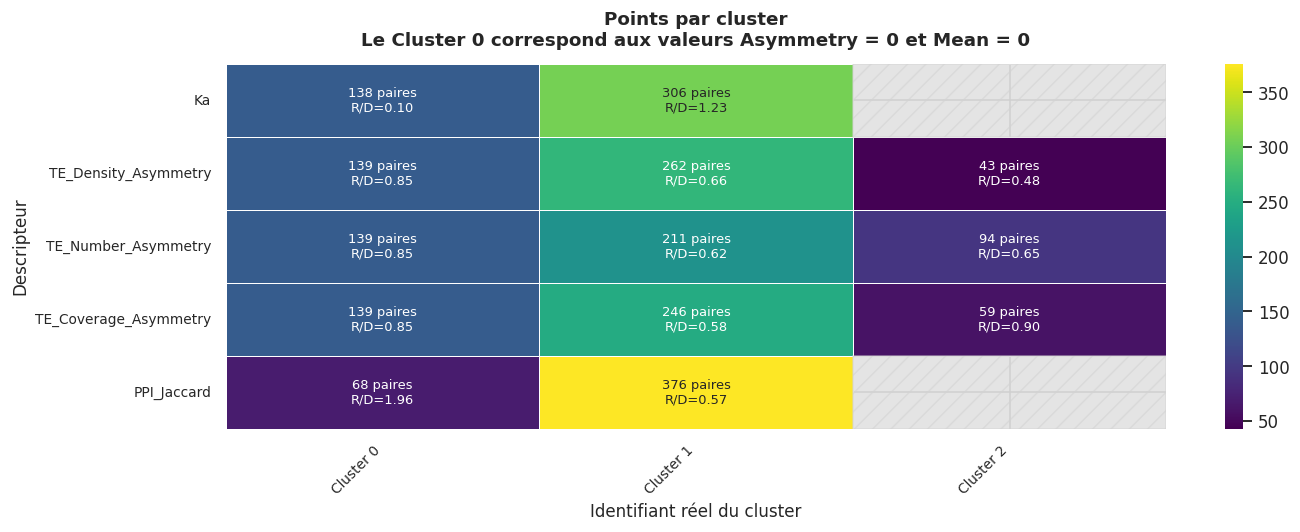

In [16]:
# Heatmap
fig, ax = plt.subplots(figsize=(13, 5))

nan_mask = cluster_comparison.isna()

sns.heatmap(
    cluster_comparison,
    annot=annot_matrix,
    fmt="",
    cmap="viridis",
    cbar=True,
    mask=nan_mask,
    linewidths=0.5,
    linecolor="white",
    ax=ax,
    annot_kws={"size": 8.5}
)

# Hachures pour les clusters absents
for row_index in range(cluster_comparison.shape[0]):
    for column_index in range(cluster_comparison.shape[1]):
        if nan_mask.iloc[row_index, column_index]:
            ax.add_patch(
                plt.Rectangle(
                    (column_index, row_index),
                    1,
                    1,
                    fill=True,
                    color="lightgrey",
                    hatch="//",
                    alpha=0.6
                )
            )

ax.set_title(
    "Points par cluster\n"
    "Le Cluster 0 correspond aux valeurs Asymmetry = 0 et Mean = 0",
    fontsize=12,
    fontweight="bold",
    pad=12
)

ax.set_xlabel("Identifiant réel du cluster", fontsize=11)
ax.set_ylabel("Descripteur", fontsize=11)

ax.set_xticklabels(
    columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    selected_descriptors,
    rotation=0,
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "Plots/kmeans/lda/cluster_comparison_ratio_heatmap_actual_ids_silhouette.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Classement des clusters par centre décroissant pour chaque descripteur

X_all_scaled_df = pd.DataFrame(
    X_all_scaled,
    columns=X_all.columns,
    index=X_train.index
)

ordered_clusters_by_descriptor = {}
cluster_centers_by_descriptor = {}
ordered_rows = []

for descriptor in selected_descriptors:
    labels = labels_by_descriptor[descriptor]

    valid_mask = (
        labels.notna()
        & X_all_scaled_df[descriptor].notna()
    )

    values = X_all_scaled_df.loc[valid_mask, descriptor]
    labels_valid = labels.loc[valid_mask].astype(int)

    centers = values.groupby(labels_valid).mean()
    ordered_clusters = centers.sort_values(
        ascending=False
    ).index.tolist()

    ordered_clusters_by_descriptor[descriptor] = ordered_clusters
    cluster_centers_by_descriptor[descriptor] = centers

    classification_valid = classifications.loc[valid_mask]

    row_sizes = {}
    row_ratios = {}

    for cluster_id in ordered_clusters:
        cluster_mask = labels_valid == cluster_id

        n_pairs = int(cluster_mask.sum())
        n_redondant = int(
            ((classification_valid == 0) & cluster_mask).sum()
        )
        n_divergent = int(
            ((classification_valid == 1) & cluster_mask).sum()
        )

        ratio = (
            n_redondant / n_divergent
            if n_divergent > 0
            else np.inf
        )

        row_sizes[cluster_id] = n_pairs
        row_ratios[cluster_id] = ratio

    ordered_rows.append({
        "descriptor": descriptor,
        "clusters": ordered_clusters,
        "sizes": row_sizes,
        "ratios": row_ratios
    })


# Nombre maximal de clusters
max_clusters = max(
    len(row["clusters"])
    for row in ordered_rows
)

rank_columns = [
    f"Rang {rank}"
    for rank in range(1, max_clusters + 1)
]

cluster_comparison_ordered = pd.DataFrame(
    np.nan,
    index=selected_descriptors,
    columns=rank_columns,
    dtype=float
)

annotations_ordered = pd.DataFrame(
    "",
    index=selected_descriptors,
    columns=rank_columns,
    dtype=object
)

cluster_labels_ordered = pd.DataFrame(
    "",
    index=selected_descriptors,
    columns=rank_columns,
    dtype=object
)


for row in ordered_rows:
    descriptor = row["descriptor"]

    for rank, cluster_id in enumerate(row["clusters"]):
        column = f"Rang {rank + 1}"

        n_pairs = row["sizes"][cluster_id]
        ratio = row["ratios"][cluster_id]
        center = cluster_centers_by_descriptor[
            descriptor
        ].loc[cluster_id]

        cluster_comparison_ordered.loc[
            descriptor, column
        ] = n_pairs

        cluster_labels_ordered.loc[
            descriptor, column
        ] = f"Cluster {cluster_id}"

        ratio_text = (
            f"{ratio:.2f}"
            if not np.isinf(ratio)
            else "inf"
        )

        annotations_ordered.loc[
            descriptor, column
        ] = (
            f"Cluster {cluster_id}\n"
            f"{n_pairs} paires\n"
            f"R/D={ratio_text}"
        )


# Affichage de l'ordre des centres
centers_ordered_df = pd.DataFrame(
    {
        descriptor: pd.Series(
            cluster_centers_by_descriptor[descriptor]
            .sort_values(ascending=False)
            .values
        )
        for descriptor in selected_descriptors
    }
)

display(centers_ordered_df)

,Ka,TE_Density_Asymmetry,TE_Number_Asymmetry,TE_Coverage_Asymmetry,PPI_Jaccard
0,1.279354,2.327148,1.554852,1.988543,2.042981
1,-0.576964,0.071482,-0.135514,-0.012115,-0.369475
2,NaN,-0.854645,-0.845775,-0.822616,NaN


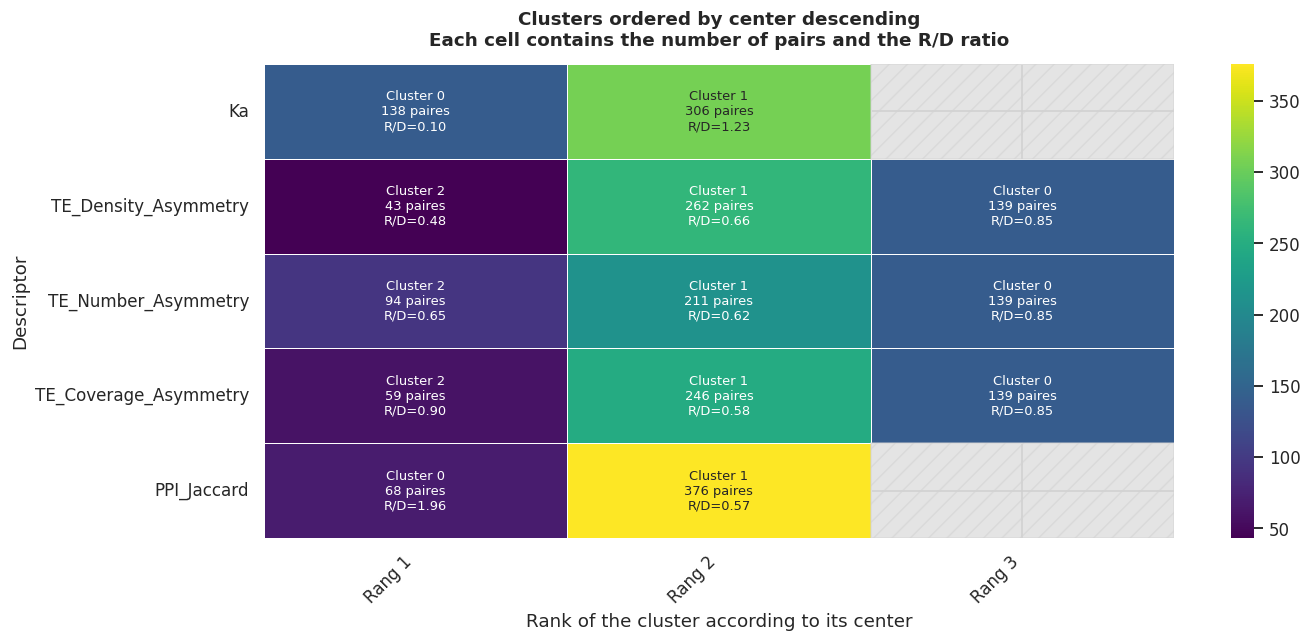

In [18]:
# Heatmap du nombre de paires
fig, ax = plt.subplots(figsize=(13, 6))

nan_mask = cluster_comparison_ordered.isna()

sns.heatmap(
    cluster_comparison_ordered,
    annot=annotations_ordered,
    fmt="",
    cmap="viridis",
    cbar=True,
    mask=nan_mask,
    linewidths=0.5,
    linecolor="white",
    ax=ax,
    annot_kws={"size": 8.5}
)

# Hachures pour les rangs inexistants
for row_index in range(
    cluster_comparison_ordered.shape[0]
):
    for column_index in range(
        cluster_comparison_ordered.shape[1]
    ):
        if nan_mask.iloc[row_index, column_index]:
            ax.add_patch(
                plt.Rectangle(
                    (column_index, row_index),
                    1,
                    1,
                    fill=True,
                    color="lightgrey",
                    hatch="//",
                    alpha=0.6
                )
            )

ax.set_title(
    "Clusters ordered by center descending\n"
    "Each cell contains the number of pairs and the R/D ratio",
    fontsize=12,
    fontweight="bold",
    pad=12
)

ax.set_xlabel(
    "Rank of the cluster according to its center"
)
ax.set_ylabel("Descriptor")

ax.set_xticklabels(
    rank_columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    selected_descriptors,
    rotation=0
)

plt.tight_layout()
plt.savefig(
    "Plots/kmeans/lda/cluster_ordered_heatmap_silhouette.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Matrices d'adjacences

In [19]:
family_adjacency_matrices = {}

for family_name in X_top_5_scaled.columns:

    if family_name in ["Ka", "PPI_Jaccard"]:
        optimal_k = 2
    else:
        optimal_k = 3

    X_family = X_top_5_scaled[[family_name]]

    kmeans_family = KMeans(
        n_clusters=optimal_k,
        n_init=n_init,
        random_state=random_state,
        init="k-means++"
    )

    labels_family = kmeans_family.fit_predict(X_family)

    Z_family_binary = pd.get_dummies(labels_family).astype(int)

    adjacency_matrix = (
        Z_family_binary.values @ Z_family_binary.values.T
    )

    np.fill_diagonal(adjacency_matrix, 0)

    family_adjacency_matrices[family_name] = adjacency_matrix

    print(
        f"{family_name} : {adjacency_matrix.shape}, "
        f"{adjacency_matrix.sum() / 2:.0f} paires"
    )

Ka : (444, 444), 56118 paires
TE_Density_Asymmetry : (444, 444), 49518 paires
TE_Number_Asymmetry : (444, 444), 48421 paires
TE_Coverage_Asymmetry : (444, 444), 50317 paires
PPI_Jaccard : (444, 444), 72778 paires


In [20]:
for family_name, adjacency_matrix in family_adjacency_matrices.items():

    adjacency_df = pd.DataFrame(
        adjacency_matrix,
        index=X_top_5_scaled.index,
        columns=X_top_5_scaled.index
    )

    adjacency_df.to_csv(
        f"Données/adjacency/lda/adjacency_matrix_silh_{family_name}.csv"
    )

    print(f"Matrice sauvegardée pour : {family_name}")

Matrice sauvegardée pour : Ka
Matrice sauvegardée pour : TE_Density_Asymmetry
Matrice sauvegardée pour : TE_Number_Asymmetry
Matrice sauvegardée pour : TE_Coverage_Asymmetry
Matrice sauvegardée pour : PPI_Jaccard


### Matrice agrégées

In [21]:
family_groups = {
    "Ka": ["Ka"],
    "TE": [
        "TE_Number_Asymmetry",
        "TE_Density_Asymmetry",
        "TE_Coverage_Asymmetry"
    ],
    "PPI": [
        "PPI_Jaccard"
    ]
}

group_adjacency_matrices = {}

for group_name, descriptors in family_groups.items():

    available_descriptors = [
        descriptor
        for descriptor in descriptors
        if descriptor in family_adjacency_matrices
    ]

    if not available_descriptors:
        print(f"Aucune matrice disponible pour {group_name}")
        continue

    group_matrix = np.sum(
        [
            family_adjacency_matrices[descriptor]
            for descriptor in available_descriptors
        ],
        axis=0
    )

    group_adjacency_matrices[group_name] = group_matrix

    print(
        f"{group_name} : "
        f"{available_descriptors} -> {group_matrix.shape}"
    )

Ka : ['Ka'] -> (444, 444)
TE : ['TE_Number_Asymmetry', 'TE_Density_Asymmetry', 'TE_Coverage_Asymmetry'] -> (444, 444)
PPI : ['PPI_Jaccard'] -> (444, 444)


In [22]:
# Compter le nombre de paires ayant une valeur 0, 1 ou 2
# dans chaque matrice agrégée par famille

for family_name, matrix in group_adjacency_matrices.items():
    matrix = np.asarray(matrix)

    print(f"\nFamille : {family_name}")

    for value in [0, 1, 2, 3]:
        count_pairs = np.sum(matrix == value) / 2
        print(
            f"Nombre de paires avec la valeur {value} : "
            f"{int(count_pairs):,}"
        )


Famille : Ka
Nombre de paires avec la valeur 0 : 42,450
Nombre de paires avec la valeur 1 : 56,118
Nombre de paires avec la valeur 2 : 0
Nombre de paires avec la valeur 3 : 0

Famille : TE
Nombre de paires avec la valeur 0 : 33,706
Nombre de paires avec la valeur 1 : 15,458
Nombre de paires avec la valeur 2 : 15,414
Nombre de paires avec la valeur 3 : 33,990

Famille : PPI
Nombre de paires avec la valeur 0 : 25,790
Nombre de paires avec la valeur 1 : 72,778
Nombre de paires avec la valeur 2 : 0
Nombre de paires avec la valeur 3 : 0


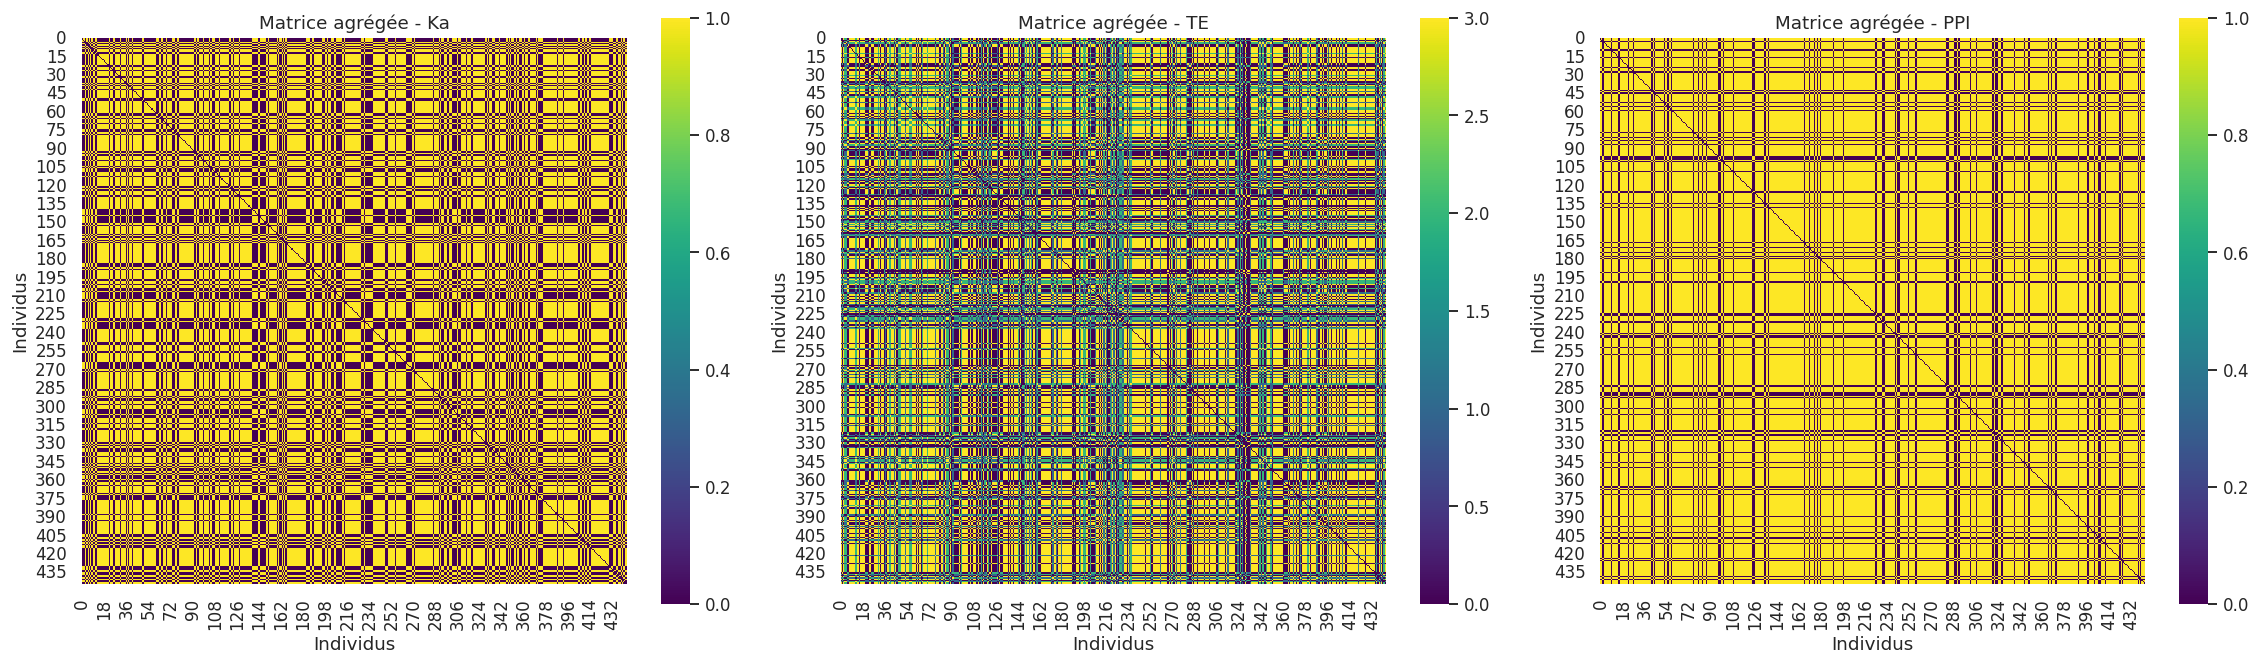

In [23]:
fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=True
    )

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

In [24]:
# Récupération des matrices agrégées par famille
matrix_ka = np.asarray(group_adjacency_matrices["Ka"])
matrix_te = np.asarray(group_adjacency_matrices["TE"])
matrix_ppi = np.asarray(group_adjacency_matrices["PPI"])

# Vérification des dimensions
assert matrix_ka.shape == matrix_te.shape == matrix_ppi.shape

# Sommes deux à deux
aggregation_pairwise = {
    "Ka_TE": matrix_ka + matrix_te,
    "TE_PPI": matrix_te + matrix_ppi,
    "Ka_PPI": matrix_ka + matrix_ppi,
}

# Somme des trois familles
aggregation_all = matrix_ka + matrix_te + matrix_ppi

# Affichage des résultats
for name, matrix in aggregation_pairwise.items():
    print(f"{name} : forme {matrix.shape}")

Ka_TE : forme (444, 444)
TE_PPI : forme (444, 444)
Ka_PPI : forme (444, 444)


In [25]:
# Compter les valeurs de 0 à 4 dans chaque matrice pairwise

for matrix_name, matrix in aggregation_pairwise.items():
    matrix = np.asarray(matrix)

    print(f"\nMatrice : {matrix_name}")

    for value in range(5):
        count_pairs = np.sum(matrix == value) / 2

        print(
            f"Valeur {value} : "
            f"{int(count_pairs):,} paires"
        )


Matrice : Ka_TE
Valeur 0 : 14,848 paires
Valeur 1 : 25,478 paires
Valeur 2 : 15,319 paires
Valeur 3 : 23,434 paires
Valeur 4 : 19,489 paires

Matrice : TE_PPI
Valeur 0 : 8,736 paires
Valeur 1 : 29,136 paires
Valeur 2 : 14,957 paires
Valeur 3 : 20,972 paires
Valeur 4 : 24,767 paires

Matrice : Ka_PPI
Valeur 0 : 9,816 paires
Valeur 1 : 48,608 paires
Valeur 2 : 40,144 paires
Valeur 3 : 0 paires
Valeur 4 : 0 paires


In [26]:
# Additionner les matrices d'adjacence de toutes les descripteurs et compter les nombres dans la matrice résultante
total_adjacency_sum = np.zeros_like(list(family_adjacency_matrices.values())[0])
for adjacency_matrix in family_adjacency_matrices.values():
    total_adjacency_sum += adjacency_matrix

num_zeros = (np.sum(total_adjacency_sum == 0)  - 444 )/ 2 # Nombre de paires de points dans le même cluster pour exactement 0 descripteurs
num_ones = np.sum(total_adjacency_sum == 1) / 2 # Nombre de paires de points dans le même cluster pour exactement 1 descripteur
num_twos = np.sum(total_adjacency_sum == 2) / 2 # Nombre de paires de points dans le même cluster pour exactement 2 descripteurs
num_threes = np.sum(total_adjacency_sum == 3) / 2 # Nombre de paires de points dans le même cluster pour exactement 3 descripteurs
num_fours = np.sum(total_adjacency_sum == 4) / 2 # Nombre de paires de points dans le même cluster pour exactement 4 descripteurs
num_fives = np.sum(total_adjacency_sum == 5) / 2 # Nombre de paires de points dans le même cluster pour exactement 5 descripteurs

print(f"Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: {num_zeros:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 1 descripteur: {num_ones:.0f}")
print(f"\nNombre de paires de points dans le même cluster pour exactement 2 descripteurs: {num_twos:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: {num_threes:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: {num_fours:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: {num_fives:.0f}")

Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: 3273
Nombre de paires de points dans le même cluster pour exactement 1 descripteur: 18141

Nombre de paires de points dans le même cluster pour exactement 2 descripteurs: 22623
Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: 17197
Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: 23386
Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: 13726


In [27]:
num_twos + num_threes + num_fours + num_ones + num_zeros + num_fives

np.float64(98346.0)

In [28]:
print("\nDistribution des valeurs dans la matrice :")
total_count = 0
total_pairs = (total_adjacency_sum.size - 444) / 2

for v in range(6):
    if v == 0:
        count = np.sum(total_adjacency_sum == v) - 444
        count = count / 2
    else:
        count = np.sum(total_adjacency_sum == v) / 2

    pct = 100 * count / total_pairs
    print(f"  Valeur {v} : {int(count):,} paires ({pct:.1f}%)")
    total_count += count



Distribution des valeurs dans la matrice :
  Valeur 0 : 3,273 paires (3.3%)
  Valeur 1 : 18,141 paires (18.4%)
  Valeur 2 : 22,623 paires (23.0%)
  Valeur 3 : 17,197 paires (17.5%)
  Valeur 4 : 23,386 paires (23.8%)
  Valeur 5 : 13,726 paires (14.0%)
